# 주택 가격 예측하기

메인퀘스트에 오신 것을 환영합니다!

이번 퀘스트의 목표는 여러 특성들을 종합적으로 고려하여 가장 주택 가격을 잘 예측하는 회귀모델을 만드는 것입니다.

- 예측할 값(y): SalePrice
- 평가지표: RMSE

예시 형식:
~~~
Id,SalePrice
1461,169000.1
1462,187724.1233
1463,175221
etc.
~~~

---

**이 노트북은** `Test_Notebook_House_Prices_Prediction_xxx` 1~4번 노트북에서 시도한 것들을 이어받아 만든 최종본입니다. 원본 노트북의 흐름(데이터 확인 → 전처리 → 모델 설정 및 학습 → 테스트 데이터 예측 및 제출)을 그대로 따릅니다.

| 단계 | 내용 | 리더보드 RMSE |
|---|---|---|
| 노트북 1 | 중앙값/최빈값 일괄 대체 + 원-핫 + LinearRegression | (검증 39,135.83) |
| 노트북 2 | 누수 없는 Pipeline, 파생 피처, Ridge·ElasticNet·GradientBoosting 비교 | 23,022.54 |
| 노트북 3 | 동네별 `LotFrontage` 대체 추가 | — |
| 노트북 4 | CatBoost(범주형 직접 처리) | 약 23,730 |
| 이 노트북 1~6장 | 전처리 재설계 + Lasso 피처 선택 + 선형 회귀 | 19,934.34 |
| 이 노트북 7장 | 4개 모델 블렌드 v2 / v3 | 18,796.99 / 19,105.91 |
| 이 노트북 10장 | 리더보드 피드백으로 제출물 조합 | **17,994.56** |

모델로서의 성능은 7장까지이고, 10장은 리더보드 점수를 이용해 제출물을 조합한 단계입니다. 둘을 구분해서 읽어 주세요.

### 퀘스트 평가 기준과 노트북 위치

| 평가 기준 | 위치 |
|---|---|
| SalePrice와 주요 변수 분포 시각화 | 2장, 2-1장 |
| 결측치·이상치 처리, 스케일링·인코딩 | 1장(결측치), 3장(이상치), 4장(`RobustScaler`, 순서형·원-핫 인코딩) |
| 3개 이상 모델 학습 및 성능 비교 | 6장(선형 계열 7종), 7장(SVR·GradientBoosting), 8장(CatBoost) |
| 앙상블 결합 및 성능 비교 | 7장(OOF 기반 가중 블렌드, 단일 모델과 비교), 10장(제출물 조합) |
| 규제 추가, 트리 깊이·학습률 조정 | 6-1장(Ridge/Lasso α), 6-2장(GradientBoosting 깊이×학습률) |

최종 제출물(`submission.csv`)은 10장에서 만들어지며 리더보드 RMSE는 17,994.56입니다.

## 데이터 확인 및 불러오기

In [1]:
import numpy as np, pandas as pd, warnings
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LassoCV
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import KFold
warnings.filterwarnings('ignore')
SEED = 42

train_df = pd.read_csv('modulabs-di/train.csv')
test_df = pd.read_csv('modulabs-di/test.csv')
print(train_df.shape, test_df.shape)

(1168, 81) (292, 80)


특성이 너무 많습니다! 어떻게 하면 좋을까요?

참고로 각각의 특성은 다음을 나타냅니다.

| 변수명               | 설명 (한국어)                         |
| ----------------- | -------------------------------- |
| **SalePrice**     | 주택의 판매 가격(달러). 예측해야 하는 타겟 변수     |
| **MSSubClass**    | 건물 등급(건물 종류 분류)                  |
| **MSZoning**      | 토지 용도 구분(일반적인 구역 분류)             |
| **LotFrontage**   | 도로에 접한 토지 길이 (피트 단위)             |
| **LotArea**       | 토지 면적 (평방 피트)                    |
| **Street**        | 도로 접근 방식                         |
| **Alley**         | 골목(후면 도로) 접근 방식                  |
| **LotShape**      | 토지의 전반적인 모양                      |
| **LandContour**   | 토지의 평탄도                          |
| **Utilities**     | 사용 가능한 공공시설(전기, 수도 등)            |
| **LotConfig**     | 토지 배치 형태                         |
| **LandSlope**     | 토지의 경사도                          |
| **Neighborhood**  | Ames 시 내의 물리적 위치(주변 지역)          |
| **Condition1**    | 주요 도로·철도에 대한 근접도                 |
| **Condition2**    | 두 번째 주요 도로·철도에 대한 근접도            |
| **BldgType**      | 주거 건물 유형 (단독, 다세대 등)             |
| **HouseStyle**    | 주택의 건축 양식                        |
| **OverallQual**   | 자재 및 마감 품질 종합 평가                 |
| **OverallCond**   | 주택의 전반적인 상태 평가                   |
| **YearBuilt**     | 최초 건축 연도                         |
| **YearRemodAdd**  | 리모델링/개조 연도                       |
| **RoofStyle**     | 지붕 스타일                           |
| **RoofMatl**      | 지붕 재료                            |
| **Exterior1st**   | 외장 마감재(주 재료)                     |
| **Exterior2nd**   | 외장 마감재(보조 재료, 2번째)               |
| **MasVnrType**    | 석조 베니어 타입                        |
| **MasVnrArea**    | 석조 베니어 면적 (평방 피트)                |
| **ExterQual**     | 외장재 품질 평가                        |
| **ExterCond**     | 외장재 상태 평가                        |
| **Foundation**    | 기초(Foundation) 유형                |
| **BsmtQual**      | 지하실 높이 평가                        |
| **BsmtCond**      | 지하실 상태 평가                        |
| **BsmtExposure**  | 지하실 외부 노출 여부(출입구/창문 등)           |
| **BsmtFinType1**  | 주요 지하실 마감 구역 유형                  |
| **BsmtFinSF1**    | 주요 지하실 마감 면적 (평방 피트)             |
| **BsmtFinType2**  | 보조 지하실 마감 구역 유형                  |
| **BsmtFinSF2**    | 보조 지하실 마감 면적 (평방 피트)             |
| **BsmtUnfSF**     | 미완성 지하실 면적 (평방 피트)               |
| **TotalBsmtSF**   | 지하실 전체 면적 (평방 피트)                |
| **Heating**       | 난방 시스템 종류                        |
| **HeatingQC**     | 난방 품질 및 상태                       |
| **CentralAir**    | 중앙 에어컨 설치 여부                     |
| **Electrical**    | 전기 시스템 종류                        |
| **1stFlrSF**      | 1층 면적 (평방 피트)                    |
| **2ndFlrSF**      | 2층 면적 (평방 피트)                    |
| **LowQualFinSF**  | 저품질 마감 공간 면적 (전체 층 합산)           |
| **GrLivArea**     | 지상(Above grade) 생활 공간 면적 (평방 피트) |
| **BsmtFullBath**  | 지하실 완비 욕실 수                      |
| **BsmtHalfBath**  | 지하실 반 욕실 수                       |
| **FullBath**      | 지상 완비 욕실 수                       |
| **HalfBath**      | 지상 반 욕실 수                        |
| **Bedroom**       | 지하실 제외 침실 수                      |
| **Kitchen**       | 주방 수                             |
| **KitchenQual**   | 주방 품질                            |
| **TotRmsAbvGrd**  | 지상 전체 방 개수 (욕실 제외)               |
| **Functional**    | 주택 기능성 평가                        |
| **Fireplaces**    | 벽난로 개수                           |
| **FireplaceQu**   | 벽난로 품질                           |
| **GarageType**    | 차고 위치(유형)                        |
| **GarageYrBlt**   | 차고 건축 연도                         |
| **GarageFinish**  | 차고 내부 마감 상태                      |
| **GarageCars**    | 차고 크기 (주차 가능 차량 수)               |
| **GarageArea**    | 차고 면적 (평방 피트)                    |
| **GarageQual**    | 차고 품질                            |
| **GarageCond**    | 차고 상태                            |
| **PavedDrive**    | 포장 진입로 여부                        |
| **WoodDeckSF**    | 목재 데크 면적 (평방 피트)                 |
| **OpenPorchSF**   | 오픈 현관 면적 (평방 피트)                 |
| **EnclosedPorch** | 밀폐된 현관 면적 (평방 피트)                |
| **3SsnPorch**     | 3계절용 현관 면적 (평방 피트)               |
| **ScreenPorch**   | 스크린 현관 면적 (평방 피트)                |
| **PoolArea**      | 수영장 면적 (평방 피트)                   |
| **PoolQC**        | 수영장 품질                           |
| **Fence**         | 울타리 품질                           |
| **MiscFeature**   | 기타 특수 기능                         |
| **MiscVal**       | 기타 기능의 금전적 가치                    |
| **MoSold**        | 판매 월                             |
| **YrSold**        | 판매 연도                            |
| **SaleType**      | 판매 유형                            |
| **SaleCondition** | 판매 조건                            |


In [2]:
train_df.head(3)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,968,20,RL,NaN,7390,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,7,1955,1955,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,151.0,TA,TA,CBlock,TA,TA,No,ALQ,902,Unf,0,196,1098,GasA,TA,Y,SBrkr,1098,0,0,1098,1,0,1,0,3,1,TA,6,Typ,0,NaN,Attchd,1955.0,Unf,1,260,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,7,2008,WD,Normal,135000
1,739,90,RL,60.0,10800,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Edwards,Norm,Norm,Duplex,1Story,5,5,1987,1988,Gable,CompShg,Plywood,Plywood,NaN,0.0,TA,TA,CBlock,Gd,Gd,Gd,GLQ,1200,Unf,0,0,1200,GasA,TA,Y,SBrkr,1200,0,0,1200,3,0,3,0,3,1,TA,5,Typ,0,NaN,NaN,NaN,NaN,0,0,NaN,NaN,Y,120,0,0,0,0,0,NaN,NaN,NaN,0,3,2009,WD,Alloca,179000
2,696,20,RL,54.0,13811,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Timber,Norm,Norm,1Fam,1Story,6,6,1987,1987,Gable,CompShg,HdBoard,HdBoard,BrkFace,72.0,TA,TA,CBlock,Gd,Gd,No,GLQ,980,LwQ,40,92,1112,GasA,Gd,Y,SBrkr,1137,0,0,1137,1,0,2,0,2,1,Gd,5,Typ,1,TA,Attchd,1987.0,Unf,2,551,TA,TA,Y,125,0,0,0,0,0,NaN,NaN,NaN,0,7,2006,WD,Normal,176000


In [3]:
print(train_df.isnull().sum())

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      218
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64


결측치 개수만 봐서는 어떻게 채워야 할지 알 수 없습니다. 아래에서 **왜 비어 있는지**(1장), **분포가 어떤지**(2장), **튀는 값이 있는지**(3장)를 먼저 확인합니다.

### 1. 결측치는 세 종류다

- **구조적 결측**: 설명서상 NA = "시설 없음" (`Alley`, `Fence`, `PoolQC`, `FireplaceQu`, 차고·지하실 계열, `MasVnrType`). 최빈값으로 채우면 차고 없는 집에 차고 품질이 생깁니다 → `'None'` / 0.
- **진짜 누락**: 시설은 있는데 값만 빈 경우 (지하실이 있는데 `BsmtExposure`가 NA, 베니어 면적이 있는데 `MasVnrType`이 NA, `Electrical` 1건) → *시설이 있는 집들* 사이의 최빈값.
- **추정이 필요한 수치**: `LotFrontage` (18.7% 결측).

In [4]:
miss = pd.DataFrame({'train': train_df.isna().sum(), 'test': test_df.isna().sum()})
display(miss[(miss.train > 0) | (miss.test > 0)].sort_values('train', ascending=False))
print('지하실은 있는데 BsmtExposure가 빈 행:', (train_df.BsmtExposure.isna() & (train_df.TotalBsmtSF > 0)).sum())
print('베니어 면적 > 0 인데 MasVnrType이 빈 행:', (train_df.MasVnrType.isna() & (train_df.MasVnrArea > 0)).sum())
print('차고 면적 > 0 인데 GarageType이 빈 행:', (train_df.GarageType.isna() & (train_df.GarageArea > 0)).sum())

지하실은 있는데 BsmtExposure가 빈 행: 1
베니어 면적 > 0 인데 MasVnrType이 빈 행: 4
차고 면적 > 0 인데 GarageType이 빈 행: 0


,train,test
PoolQC,1162,291.0
MiscFeature,1120,286.0
Alley,1098,271.0
Fence,941,238.0
MasVnrType,694,178.0
FireplaceQu,545,145.0
LotFrontage,218,41.0
GarageYrBlt,69,12.0
GarageType,69,12.0
GarageFinish,69,12.0


### 2. 분포 확인 — 무엇을 어떻게 채우고 변환할까

- `SalePrice`: 왜도 1.96 → 로그를 취하면 0.09. 타깃은 로그로 학습하고 예측 시 `exp`로 복원합니다.
- `LotFrontage`: 왜도 2.49로 정규분포가 아니므로 평균 대체는 부적절. 로그 공간에서 `LotArea`와 상관 0.76 → **log(LotFrontage) ~ log(LotArea) + LotConfig** 회귀로 추정하고, 결측 여부는 별도 플래그로 남깁니다 (결측 행은 CulDSac 비율이 4% → 18%로 높아 무작위 결측이 아님).

In [5]:
from scipy import stats
y_raw = train_df['SalePrice']
print(f"SalePrice 왜도 {y_raw.skew():.2f} → log 후 {np.log(y_raw).skew():.2f}")
lf = train_df['LotFrontage'].dropna()
print(f"LotFrontage 왜도 {lf.skew():.2f}, Shapiro p={stats.shapiro(lf)[1]:.1e}")
print('log 공간 상관:', np.log(train_df[['LotFrontage', 'LotArea']].dropna()).corr().iloc[0, 1].round(3))
print(train_df.groupby(train_df.LotFrontage.isna())['LotConfig'].value_counts(normalize=True).round(2).unstack())
num_skew = train_df.select_dtypes('number').drop(columns=['Id', 'SalePrice']).skew().sort_values(ascending=False)
display(num_skew.head(15).round(2).to_frame('skew'))

SalePrice 왜도 1.96 → log 후 0.09
LotFrontage 왜도 2.49, Shapiro p=1.9e-28
log 공간 상관: 0.76
LotConfig    Corner  CulDSac   FR2  FR3  Inside
LotFrontage                                    
False          0.17     0.04  0.02  0.0    0.77
True           0.25     0.18  0.05  NaN    0.52


,skew
MiscVal,22.13
PoolArea,14.40
LotArea,11.11
3SsnPorch,11.05
LowQualFinSF,9.62
BsmtFinSF2,4.51
KitchenAbvGr,4.49
BsmtHalfBath,4.14
ScreenPorch,3.98
EnclosedPorch,3.10


### 2-1. 시각화로 보는 분포

그래프 라벨은 영어로 적었습니다.

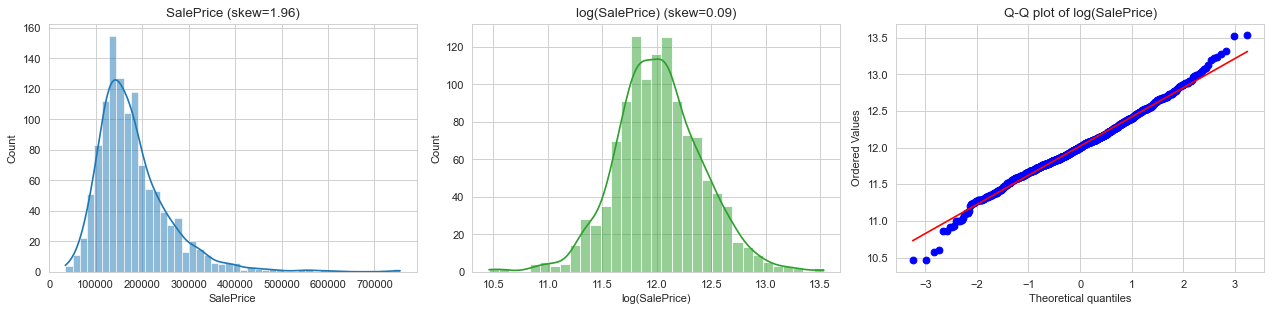

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

# (1) 타깃 분포: 원래 가격 vs 로그 가격
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(train_df['SalePrice'], kde=True, ax=ax[0])
ax[0].set_title(f"SalePrice (skew={train_df['SalePrice'].skew():.2f})")
sns.histplot(np.log(train_df['SalePrice']), kde=True, ax=ax[1], color='tab:green')
ax[1].set_title(f"log(SalePrice) (skew={np.log(train_df['SalePrice']).skew():.2f})"); ax[1].set_xlabel('log(SalePrice)')
stats.probplot(np.log(train_df['SalePrice']), plot=ax[2]); ax[2].set_title('Q-Q plot of log(SalePrice)')
plt.tight_layout(); plt.show()

원래 가격은 오른쪽 꼬리가 길고, 로그를 취하면 거의 대칭이 되어 Q-Q 선에 붙습니다. 그래서 타깃을 로그로 학습합니다.

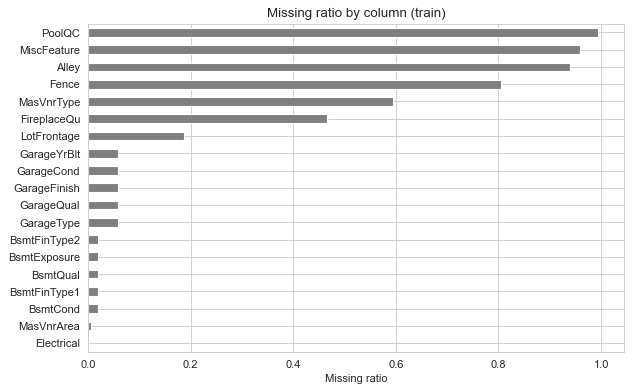

In [7]:
# (2) 결측 비율
miss_ratio = train_df.isna().mean().loc[lambda s: s > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
miss_ratio.plot.barh(ax=ax, color='tab:gray')
ax.set_xlabel('Missing ratio'); ax.set_title('Missing ratio by column (train)')
plt.tight_layout(); plt.show()

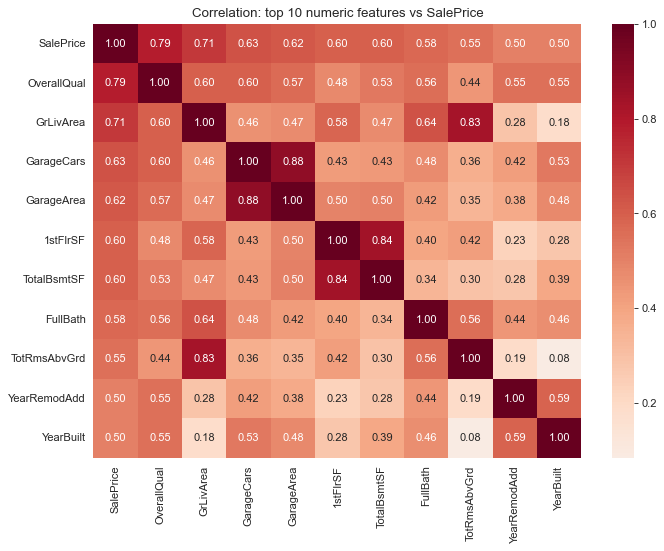

In [8]:
# (3) SalePrice와 상관이 높은 수치 변수 10개
corr = train_df.select_dtypes('number').drop(columns='Id').corr()
top = corr['SalePrice'].abs().sort_values(ascending=False).index[:11]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr.loc[top, top], annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Correlation: top 10 numeric features vs SalePrice')
plt.tight_layout(); plt.show()

`GarageCars`↔`GarageArea`, `TotalBsmtSF`↔`1stFlrSF`, `GrLivArea`↔`TotRmsAbvGrd`처럼 서로 상관이 높은 쌍이 보입니다. 4장에서 이런 중복 열은 한쪽만 남깁니다.

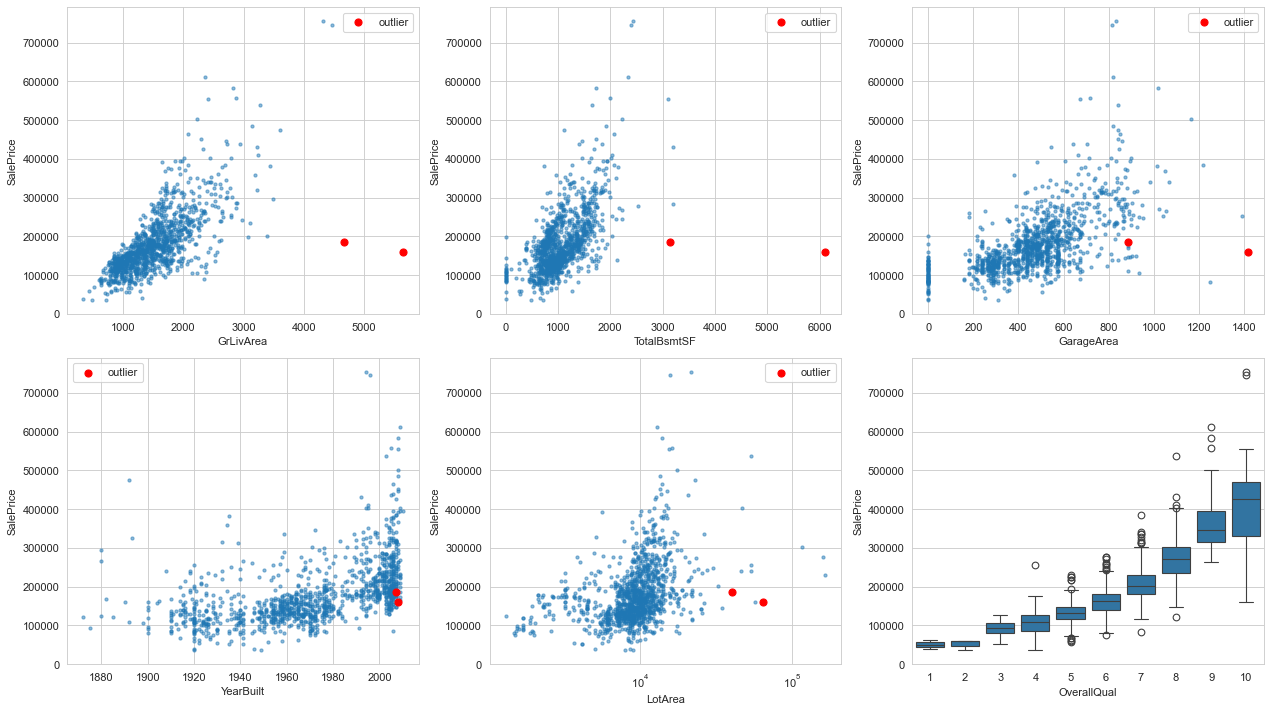

In [9]:
# (4) 주요 변수와 SalePrice의 관계 (빨간 점 = 학습에서 제외할 이상치)
is_out = (train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel()[:5], ['GrLivArea', 'TotalBsmtSF', 'GarageArea', 'YearBuilt', 'LotArea']):
    ax.scatter(train_df.loc[~is_out, col], train_df.loc[~is_out, 'SalePrice'], s=8, alpha=0.5)
    ax.scatter(train_df.loc[is_out, col], train_df.loc[is_out, 'SalePrice'], s=40, color='red', label='outlier')
    ax.set_xlabel(col); ax.set_ylabel('SalePrice')
    if col == 'LotArea': ax.set_xscale('log')
    ax.legend()
sns.boxplot(x='OverallQual', y='SalePrice', data=train_df, ax=axes[1, 2], color='tab:blue')
plt.tight_layout(); plt.show()

`GrLivArea`가 4,000을 넘는데 가격이 낮은 두 점이 전체 추세에서 크게 벗어나 있습니다. `OverallQual`은 등급이 오를수록 가격이 가파르게 오르고, 9~10 구간은 흩어짐도 큽니다.

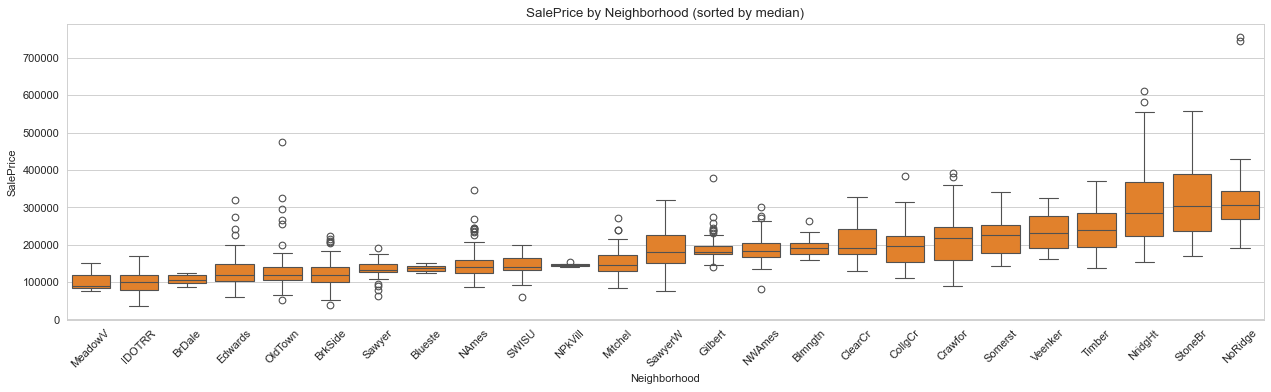

In [10]:
# (5) 동네별 가격 분포
order = train_df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
fig, ax = plt.subplots(figsize=(16, 5))
sns.boxplot(x='Neighborhood', y='SalePrice', data=train_df, order=order, ax=ax, color='tab:orange')
ax.tick_params(axis='x', rotation=45); ax.set_title('SalePrice by Neighborhood (sorted by median)')
plt.tight_layout(); plt.show()

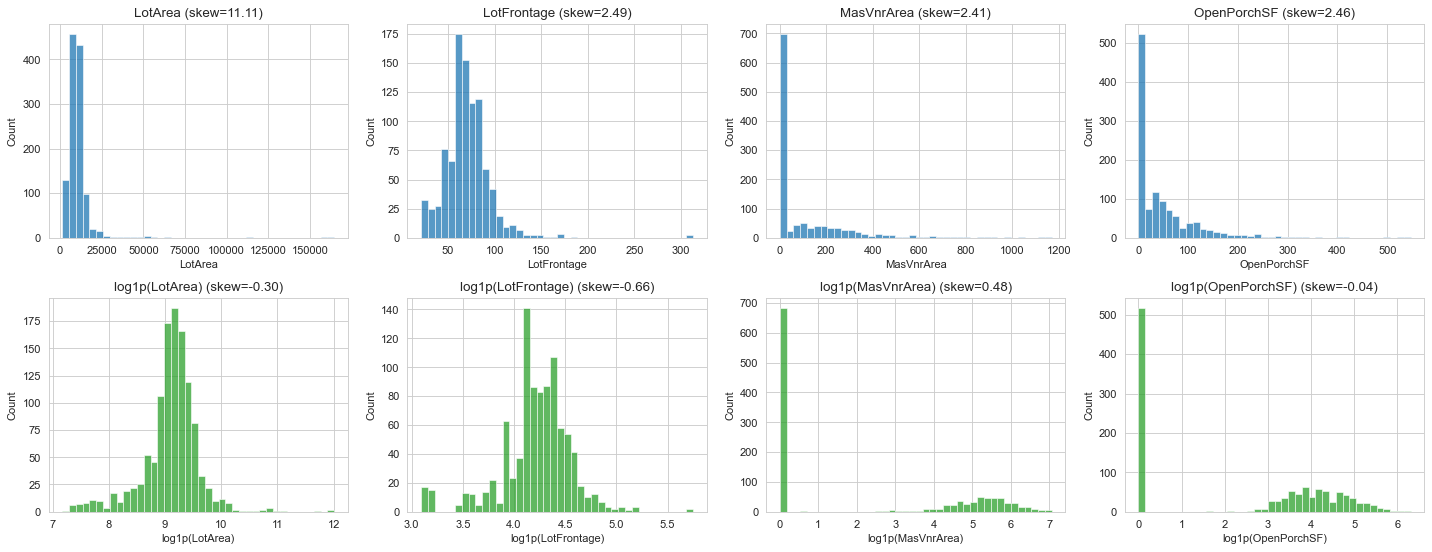

In [11]:
# (6) 왜도가 큰 수치 변수: 변환 전(위) / log1p 후(아래)
cols = ['LotArea', 'LotFrontage', 'MasVnrArea', 'OpenPorchSF']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, col in enumerate(cols):
    v = train_df[col].dropna()
    sns.histplot(v, bins=40, ax=axes[0, j]); axes[0, j].set_title(f'{col} (skew={v.skew():.2f})')
    sns.histplot(np.log1p(v), bins=40, ax=axes[1, j], color='tab:green'); axes[1, j].set_title(f'log1p({col}) (skew={np.log1p(v).skew():.2f})')
    axes[1, j].set_xlabel(f'log1p({col})')
plt.tight_layout(); plt.show()

### 3. 이상치

`GrLivArea > 4000`인데 가격이 30만 달러 미만인 집 2건(Id 1299, 524, 둘 다 Partial 판매)은 면적–가격 관계를 크게 왜곡합니다. **학습에서만 제거**합니다. 테스트에는 `GrLivArea > 4000`인 집이 없습니다(최대 3,627).

In [12]:
display(train_df.loc[train_df.GrLivArea > 4000, ['Id', 'GrLivArea', 'TotalBsmtSF', 'OverallQual', 'SaleCondition', 'SalePrice']])
print('test GrLivArea 최대:', test_df.GrLivArea.max())

test GrLivArea 최대: 3627


,Id,GrLivArea,TotalBsmtSF,OverallQual,SaleCondition,SalePrice
64,1299,5642,6110,10,Partial,160000
373,524,4676,3138,10,Partial,184750
579,692,4316,2444,10,Normal,755000
647,1183,4476,2396,10,Abnorml,745000


## 전처리

전처리에서 고민해야 할 것은 많습니다.

1. 결측치
2. 이상치

원본 노트북은 "최소한의 전처리"로 수치형은 중앙값, 범주형은 최빈값으로 채웠습니다. 먼저 그 방식을 그대로 재현해 출발점을 확인합니다.

In [13]:
# 노트북 1의 방식 그대로: 중앙값/최빈값 일괄 대체 + get_dummies + LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
b = train_df.copy()
b = b.fillna(b.median(numeric_only=True))
for col in b.select_dtypes(exclude='number'):
    b[col] = b[col].fillna(b[col].mode()[0])
b = pd.get_dummies(b, drop_first=True)
Xb, yb = b.drop('SalePrice', axis=1), b['SalePrice']
Xb_tr, Xb_va, yb_tr, yb_va = train_test_split(Xb, yb, test_size=0.2, random_state=42)
base_rmse = np.sqrt(mean_squared_error(yb_va, LinearRegression().fit(Xb_tr, yb_tr).predict(Xb_va)))
print(f'노트북 1 방식의 검증 RMSE: {base_rmse:,.2f}')

노트북 1 방식의 검증 RMSE: 39,135.83


### 노트북 1~4에서 시도한 것과 남은 문제

| 노트북 | 바꾼 것 | 결과 (각 노트북에 저장된 출력) |
|---|---|---|
| 1 | 중앙값/최빈값 대체, `get_dummies`, LinearRegression | 검증 RMSE 39,135.83 |
| 2 | 전처리를 `Pipeline` 안에 넣어 누수 차단. 면적이 0일 때만 "시설 없음"으로 처리. 파생 피처(`TotalSF`, `TotalBath`, `HouseAge`, `QualityArea`, `Log_*`). Ridge / ElasticNet / GradientBoosting을 로그·원래 타깃으로 13개 비교 | 교차검증 1위 GBR depth 3 (28,625). 검증 23,169, **리더보드 23,022.54** |
| 3 | `LotFrontage`를 전체 중앙값 대신 **동네별 중앙값**으로 채우고 결측 여부 플래그 추가 | 교차검증 28,561, 검증 22,933. 개선 폭이 작음 |
| 4 | CatBoost에 범주형을 원-핫 없이 직접 전달, 로그·원래 타깃 비교 | 교차검증 28,463, 검증 21,599. 리더보드는 약 23,730으로 노트북 2보다 나쁨 |

**여기서 관찰한 것**

- 노트북 2~4에서는 선형 계열(Ridge 로그 타깃 34,028)이 트리 계열(28,600)에 크게 졌습니다. 그래서 더 강한 트리 모델(CatBoost)로 갔지만 리더보드는 좋아지지 않았습니다.
- 교차검증의 폴드 간 표준편차가 8,000~20,000으로 매우 컸습니다. 특정 폴드에서만 오차가 폭발한다는 뜻이고, 원인은 3장에서 본 **이상치 2건**이었습니다. 선형 모델은 이런 점에 특히 약합니다.
- 결측치 대체 방식(전체 중앙값 → 동네 중앙값)은 점수를 거의 바꾸지 못했습니다.

**그래서 이 노트북에서 바꾼 방향**

모델을 더 복잡하게 하는 대신 **전처리를 다시 설계해서 선형 모델을 살리는 것**입니다. 노트북 2~4에서 가져온 것(누수 없는 Pipeline, "시설 없음" 처리, 파생 피처, 로그 타깃, `LotFrontage` 결측 플래그)은 유지하고, 다음을 추가했습니다.

1. 이상치 2건을 학습에서만 제외
2. 품질 등급(`Ex > Gd > TA > Fa > Po`)을 원-핫이 아니라 순서 있는 숫자로
3. 로그 변환은 왜도가 아주 큰 피처에만 (노트북 2는 `GrLivArea`, `TotalSF`까지 `Log_*`를 추가)
4. 중복·무정보 열 정리, 희귀 범주 묶기
5. 시설은 있는데 값만 빠진 "진짜 결측"을 따로 구분

### 4. 전처리기

- 순서가 있는 품질 등급(`Ex > Gd > TA > Fa > Po`)은 숫자로, 순서 없는 범주는 원-핫(10건 미만 범주는 하나로 묶음).
- 파생 피처: `TotalSF`, `TotalBath`, `PorchSF`, `Age`, `RemodAge`, `QualSF` 등.
- 정보가 거의 없거나(`Utilities`, `Street`, `PoolQC`…) 다른 피처와 중복되는(`GarageArea`↔`GarageCars`, `1stFlrSF`/`2ndFlrSF`↔`GrLivArea`, `GarageYrBlt`↔`YearBuilt`) 열은 제거.
- 왜도가 임계값보다 큰 수치 피처만 `log1p`.

In [14]:
QUAL = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ORDINAL = {
    **{c: QUAL for c in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual',
                         'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']},
    'BsmtExposure': {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
    'BsmtFinType1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'BsmtFinType2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'GarageFinish': {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3},
    'Functional': {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7},
    'Fence': {'None': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4},
    'LotShape': {'IR3': 0, 'IR2': 1, 'IR1': 2, 'Reg': 3},
    'LandSlope': {'Sev': 0, 'Mod': 1, 'Gtl': 2},
    'PavedDrive': {'N': 0, 'P': 1, 'Y': 2},
    'CentralAir': {'N': 0, 'Y': 1},
}
# 데이터 설명서상 NA = "시설 없음"
NONE_CATS = ['Alley', 'Fence', 'MiscFeature', 'PoolQC', 'FireplaceQu', 'GarageType', 'GarageFinish',
             'GarageQual', 'GarageCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
             'BsmtFinType2', 'MasVnrType']
DROP_COLS = ['Id', 'Utilities', 'Street', 'PoolQC', 'PoolArea', 'MiscFeature', 'MiscVal',
             'GarageYrBlt', 'GarageArea', 'TotRmsAbvGrd', '1stFlrSF', '2ndFlrSF',
             'BsmtFinSF2', 'LowQualFinSF', '3SsnPorch', 'MoSold', 'YrSold', 'Condition2', 'RoofMatl',
             'Heating', 'GarageCond', 'BsmtFinType2', 'Exterior2nd', 'BsmtHalfBath']

In [15]:
class HouseCleaner(BaseEstimator, TransformerMixin):
    """결측치 의미 기반 처리 + 파생 피처 + 분포 변환. 통계량은 fit(학습 폴드)에서만 계산."""

    def __init__(self, lf_mode='reg', engineer=True, ordinal=True, log_skew=True, drop=True, skew_thr=0.75, extra=0):
        self.lf_mode, self.engineer, self.ordinal = lf_mode, engineer, ordinal
        self.log_skew, self.drop, self.skew_thr, self.extra = log_skew, drop, skew_thr, extra

    # --- 행 단위 규칙(통계 불필요) ---
    def _structural(self, X):
        df = X.copy()
        no_bsmt, no_gar = df['TotalBsmtSF'].fillna(0).eq(0), df['GarageArea'].fillna(0).eq(0)
        self._real_missing = {  # 시설은 있는데 값만 빠진 '진짜 결측' → 최빈값 대상
            'BsmtExposure': df['BsmtExposure'].isna() & ~no_bsmt,
            'BsmtFinType2': df['BsmtFinType2'].isna() & ~no_bsmt,
            'MasVnrType': df['MasVnrType'].isna() & df['MasVnrArea'].fillna(0).gt(0),
        }
        df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
        for c in ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath',
                  'GarageCars', 'GarageArea']:
            df[c] = df[c].fillna(0)
        df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])
        for c in NONE_CATS:
            df[c] = df[c].where(df[c].notna() | self._real_missing.get(c, False), 'None')
        df['MSSubClass'] = 'SC' + df['MSSubClass'].astype(int).astype(str)
        return df

    def fit(self, X, y=None):
        df = self._structural(X)
        # 진짜 결측: 시설이 있는 집들 사이의 최빈값
        self.modes_ = {c: df.loc[df[c].ne('None') & df[c].notna(), c].mode()[0] for c in self._real_missing}
        self.cat_modes_ = df.select_dtypes(exclude='number').mode().iloc[0]
        self.num_medians_ = df.select_dtypes('number').median()
        # LotFrontage: 우측 꼬리 분포 → 로그 공간에서 log(LotArea) + 필지형태로 회귀
        known = df[df['LotFrontage'].notna()]
        self.lf_global_ = known['LotFrontage'].median()
        self.lf_nbhd_ = known.groupby('Neighborhood')['LotFrontage'].median()
        self.lf_cfg_cols_ = sorted(df['LotConfig'].dropna().unique())[1:]
        self.lf_reg_ = LinearRegression().fit(self._lf_design(known), np.log(known['LotFrontage']))
        df = self._finish(df)
        num = df.select_dtypes('number')
        cand = [c for c in num.columns if num[c].nunique() > 10 and num[c].min() >= 0
                and not c.startswith(('Year', 'Age', 'Remod'))]
        sk = num[cand].skew()
        self.log_cols_ = sk[sk.abs() > self.skew_thr].index.tolist() if self.log_skew else []
        return self

    def _lf_design(self, df):
        D = pd.DataFrame({'logArea': np.log(df['LotArea'])}, index=df.index)
        for k in self.lf_cfg_cols_:
            D['cfg_' + k] = (df['LotConfig'] == k).astype(float)
        return D

    def _finish(self, df):
        for c, mask in self._real_missing.items():
            df.loc[df[c].isna(), c] = self.modes_[c]
        miss = df['LotFrontage'].isna()
        df['LotFrontageMissing'] = miss.astype(int)
        if miss.any():
            if self.lf_mode == 'reg':
                fill = np.exp(self.lf_reg_.predict(self._lf_design(df[miss])))
            elif self.lf_mode == 'nbhd':
                fill = df.loc[miss, 'Neighborhood'].map(self.lf_nbhd_).fillna(self.lf_global_).to_numpy()
            else:
                fill = self.lf_global_
            df.loc[miss, 'LotFrontage'] = fill
        for c in df.select_dtypes(exclude='number'):   # 그 외 범주형(Electrical 등) → 최빈값
            df[c] = df[c].fillna(self.cat_modes_[c])
        for c in df.select_dtypes('number'):
            df[c] = df[c].fillna(self.num_medians_.get(c, 0))
        if self.engineer:
            df['TotalSF'] = df['TotalBsmtSF'] + df['GrLivArea']
            df['TotalBath'] = df['FullBath'] + 0.5 * df['HalfBath'] + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']
            df['PorchSF'] = df[['OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'WoodDeckSF']].sum(axis=1)
            df['Age'] = (df['YrSold'] - df['YearBuilt']).clip(lower=0)
            df['RemodAge'] = (df['YrSold'] - df['YearRemodAdd']).clip(lower=0)
            df['IsNew'] = (df['YearBuilt'] == df['YrSold']).astype(int)
            df['Has2ndFlr'] = (df['2ndFlrSF'] > 0).astype(int)
            df['HasPool'] = (df['PoolArea'] > 0).astype(int)
        if self.extra:   # extra=1: 고급·신축 주택 과소예측 보정용 (v2)
            df['Qual9'] = (df['OverallQual'] >= 9).astype(int)
            df['NewSF'] = (df['SaleType'] == 'New') * (df['TotalBsmtSF'] + df['GrLivArea']) / 1000
        if self.extra >= 2:   # extra=2: 부엌 품질 × 지상 면적 (v3에서 추가)
            df['KQxSF'] = df['KitchenQual'].map(QUAL).fillna(3) * df['GrLivArea']
        if self.ordinal:
            for c, mp in ORDINAL.items():
                df[c] = df[c].map(mp).fillna(0).astype(float)
        if self.engineer and self.ordinal:
            df['QualSF'] = df['OverallQual'] * df['TotalSF']
            df['QualGrLiv'] = df['OverallQual'] * df['GrLivArea']
        if self.drop:
            df = df.drop(columns=[c for c in DROP_COLS if c in df])
        else:
            df = df.drop(columns=['Id'])
        return df

    def transform(self, X):
        df = self._finish(self._structural(X))
        for c in self.log_cols_:
            df[c] = np.log1p(df[c])
        return df

In [16]:
def make_pipe(reg, select=None, min_freq=10, **ck):
    steps = [('clean', HouseCleaner(**ck)),
             ('enc', ColumnTransformer([
                 ('num', RobustScaler(), make_column_selector(dtype_include='number')),
                 ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=min_freq,
                                       sparse_output=False), make_column_selector(dtype_exclude='number'))]))]
    if select is not None:
        steps.append(('select', SelectFromModel(Lasso(alpha=select, max_iter=50000), threshold=1e-8)))
    steps.append(('reg', reg))
    return Pipeline(steps)


OUTLIER = lambda d: (d['GrLivArea'] > 4000) & (d['SalePrice'] < 300000)


def cv_rmse(pipe, train, log_target=True, drop_out=True, seeds=(0, 1, 2), k=5):
    """원래 가격 단위 RMSE. 이상치는 학습 폴드에서만 제거하고, 점수는 (전체 / 이상치 제외) 둘 다 반환."""
    out_mask = OUTLIER(train).to_numpy()
    X, y = train.drop(columns='SalePrice'), train['SalePrice'].to_numpy(float)
    all_r, clean_r = [], []
    for s in seeds:
        pred = np.zeros(len(y))
        for tr, va in KFold(k, shuffle=True, random_state=s).split(X):
            if drop_out:
                tr = tr[~out_mask[tr]]
            m = clone(pipe).fit(X.iloc[tr], np.log(y[tr]) if log_target else y[tr])
            p = m.predict(X.iloc[va])
            pred[va] = np.exp(p) if log_target else p
        all_r.append(np.sqrt(np.mean((pred - y) ** 2)))
        clean_r.append(np.sqrt(np.mean((pred - y)[~out_mask] ** 2)))
    return np.mean(all_r), np.mean(clean_r)

### 5. 단계별 효과 (Ridge α=10, 5-fold × 3회 반복)

`excl_outlier`는 이상치 2건을 채점에서 뺀 RMSE입니다. 테스트에 그런 집이 없으므로 이 값이 리더보드에 더 가까운 추정입니다.

In [17]:
rows = []
def run(name, pipe, **kw):
    a, c = cv_rmse(pipe, train_df, **kw)
    rows.append({'설정': name, 'RMSE_all': round(a), 'RMSE_excl_outlier': round(c)})

R = Ridge(alpha=10)
base = dict(lf_mode='median', engineer=False, ordinal=False, log_skew=False, drop=False)
run('구조적 결측만 처리, 원래 타깃, 이상치 유지', make_pipe(R, min_freq=None, **base), log_target=False, drop_out=False)
run('+ 로그 타깃', make_pipe(R, min_freq=None, **base), drop_out=False)
run('+ 이상치 2건 학습 제외', make_pipe(R, min_freq=None, **base))
run('+ 순서형 인코딩·파생 피처·열 정리·희귀 범주 묶기', make_pipe(R, log_skew=False, lf_mode='median'))
run('+ 왜도 > 0.75 전부 log1p', make_pipe(R, skew_thr=0.75, lf_mode='median'))
run('+ 왜도 > 1.5 만 log1p', make_pipe(R, skew_thr=1.5, lf_mode='median'))
for m in ['median', 'nbhd', 'reg']:
    run(f'LotFrontage 대체 = {m}', make_pipe(R, skew_thr=1.5, lf_mode=m))
display(pd.DataFrame(rows))

,설정,RMSE_all,RMSE_excl_outlier
0,"구조적 결측만 처리, 원래 타깃, 이상치 유지",36072,28540
1,+ 로그 타깃,60833,25091
2,+ 이상치 2건 학습 제외,76074,20490
3,+ 순서형 인코딩·파생 피처·열 정리·희귀 범주 묶기,86026,20152
4,+ 왜도 > 0.75 전부 log1p,39323,21863
5,+ 왜도 > 1.5 만 log1p,69297,19827
6,LotFrontage 대체 = median,69297,19827
7,LotFrontage 대체 = nbhd,68433,19871
8,LotFrontage 대체 = reg,67863,19841


**읽는 법**

- 가장 큰 개선은 **로그 타깃 + 이상치 제거**에서 나옵니다.
- "정규성을 맞추려고 왜도 큰 피처를 전부 로그 변환"하면 오히려 나빠집니다. 타깃이 로그일 때 `GrLivArea`·`TotalSF`까지 로그를 취하면 초고가 대형 주택을 과소예측하기 때문입니다. 그래서 왜도가 아주 큰 피처(대지·포치·베니어 면적 등)만 변환합니다.
- `LotFrontage` 대체 방식(전체 중앙값 / 동네 중앙값 / 회귀)은 RMSE에 거의 영향이 없습니다. 회귀 대체는 해석상 타당해서 채택하지만 점수를 올리는 요인은 아닙니다.

## 모델 설정 및 학습

노트북 2~4는 후보 모델을 교차검증으로 비교해 하나를 골랐습니다. 여기서도 같은 방식으로 비교하되, 마지막에는 하나를 고르지 않고 성격이 다른 모델을 섞습니다.

### 6. 피처 선택 + 일반 회귀 모델

Lasso(L1)로 계수가 0이 되는 피처를 버리고, 남은 피처로 규제 없는 `LinearRegression`을 학습합니다. 선택도 폴드 안에서 다시 수행하므로 누수가 없습니다.

In [18]:
K = dict(skew_thr=1.5)
models = {
    'LinearRegression (전체 피처)': make_pipe(LinearRegression(), **K),
    'Lasso 선택(0.0005) → LinearRegression': make_pipe(LinearRegression(), select=0.0005, **K),
    'Lasso 선택(0.001) → LinearRegression': make_pipe(LinearRegression(), select=0.001, **K),
    'Lasso 선택(0.002) → LinearRegression': make_pipe(LinearRegression(), select=0.002, **K),
    'Ridge α=10': make_pipe(Ridge(alpha=10), **K),
    'Lasso α=0.0004': make_pipe(Lasso(alpha=0.0004, max_iter=50000), **K),
    'ElasticNet α=0.001': make_pipe(ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=50000), **K),
}
res = pd.DataFrame([{'모델': n, 'RMSE_excl_outlier': round(cv_rmse(p, train_df)[1])} for n, p in models.items()])
display(res.sort_values('RMSE_excl_outlier'))

,모델,RMSE_excl_outlier
5,Lasso α=0.0004,19661
2,Lasso 선택(0.001) → LinearRegression,19695
6,ElasticNet α=0.001,19697
4,Ridge α=10,19841
1,Lasso 선택(0.0005) → LinearRegression,19980
0,LinearRegression (전체 피처),20508
3,Lasso 선택(0.002) → LinearRegression,20597


In [19]:
# 최종 학습: 이상치 제외한 전체 학습 데이터
fit_df = train_df[~OUTLIER(train_df)]
X_fit, y_fit = fit_df.drop(columns='SalePrice'), np.log(fit_df['SalePrice'])
final = clone(models['Lasso 선택(0.001) → LinearRegression']).fit(X_fit, y_fit)

names = final['enc'].get_feature_names_out()
kept = final['select'].get_support()
print(f'전체 {len(names)}개 중 {kept.sum()}개 선택')
coef = pd.Series(final['reg'].coef_, index=[n.split('__')[1] for n in names[kept]])
display(coef.reindex(coef.abs().sort_values(ascending=False).index).head(25).round(4).to_frame('계수(log 가격, 표준화 단위)'))

전체 166개 중 64개 선택


,"계수(log 가격, 표준화 단위)"
MSZoning_infrequent_sklearn,-0.5371
Neighborhood_Crawfor,0.1186
Neighborhood_StoneBr,0.1123
QualSF,0.1047
SaleCondition_Abnorml,-0.1010
QualGrLiv,0.0878
SaleCondition_Family,-0.0804
Exterior1st_BrkFace,0.0681
Neighborhood_BrkSide,0.0634
KitchenAbvGr,-0.0540


### 6-1. 규제 강도 조정 — Ridge / Lasso의 α

α가 작으면 규제가 약해 과적합되고, 크면 계수를 지나치게 눌러 과소적합됩니다. 교차검증 RMSE가 가장 낮은 α를 찾습니다.

규제 없음: 20,508
Ridge 최적 α=10 → 19,841
Lasso 최적 α=0.0004 → 19,661


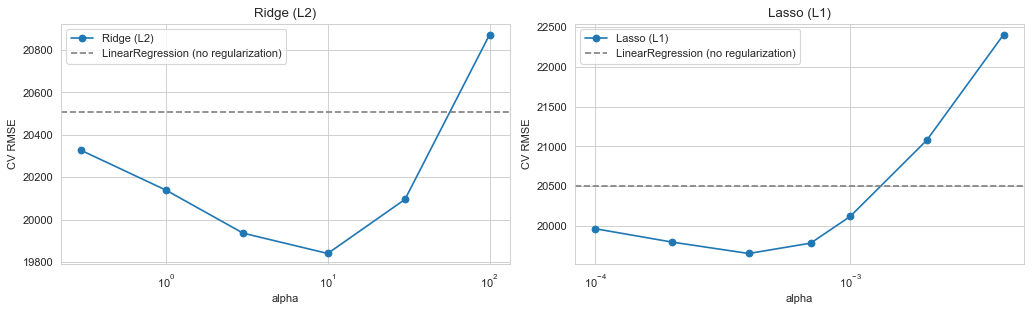

In [20]:
alphas_ridge = [0.3, 1, 3, 10, 30, 100]
alphas_lasso = [0.0001, 0.0002, 0.0004, 0.0007, 0.001, 0.002, 0.004]
ridge_cv = [cv_rmse(make_pipe(Ridge(alpha=a), **K), train_df)[1] for a in alphas_ridge]
lasso_cv = [cv_rmse(make_pipe(Lasso(alpha=a, max_iter=50000), **K), train_df)[1] for a in alphas_lasso]
noreg = cv_rmse(make_pipe(LinearRegression(), **K), train_df)[1]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a_, xs, ys, name in [(ax[0], alphas_ridge, ridge_cv, 'Ridge (L2)'), (ax[1], alphas_lasso, lasso_cv, 'Lasso (L1)')]:
    a_.semilogx(xs, ys, marker='o', label=name)
    a_.axhline(noreg, color='gray', ls='--', label='LinearRegression (no regularization)')
    a_.set_xlabel('alpha'); a_.set_ylabel('CV RMSE'); a_.set_title(name); a_.legend()
plt.tight_layout(); plt.show()
print(f'규제 없음: {noreg:,.0f}')
print(f'Ridge 최적 α={alphas_ridge[int(np.argmin(ridge_cv))]} → {min(ridge_cv):,.0f}')
print(f'Lasso 최적 α={alphas_lasso[int(np.argmin(lasso_cv))]} → {min(lasso_cv):,.0f}')

### 6-2. 트리 기반 모델 조정 — GradientBoosting의 깊이 × 학습률

트리 개수는 600으로 고정하고 `max_depth`와 `learning_rate`를 바꿔 봅니다. (5-fold 1회)

최적: max_depth=4, learning_rate=0.05 → 21,671


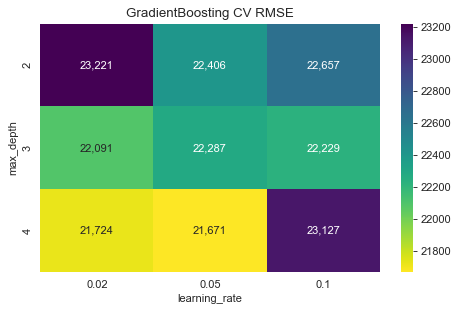

In [21]:
from sklearn.ensemble import GradientBoostingRegressor
depths, lrs = [2, 3, 4], [0.02, 0.05, 0.1]
grid = pd.DataFrame(index=pd.Index(depths, name='max_depth'), columns=pd.Index(lrs, name='learning_rate'), dtype=float)
for d in depths:
    for lr in lrs:
        gbr = GradientBoostingRegressor(n_estimators=600, learning_rate=lr, max_depth=d, subsample=0.7,
                                        max_features=0.3, min_samples_leaf=5, random_state=0)
        grid.loc[d, lr] = cv_rmse(make_pipe(gbr, **K), train_df, seeds=(0,))[1]
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(grid, annot=True, fmt=',.0f', cmap='viridis_r', ax=ax)
ax.set_title('GradientBoosting CV RMSE')
plt.tight_layout(); plt.show()
best_d, best_lr = grid.stack().idxmin()
print(f'최적: max_depth={best_d}, learning_rate={best_lr} → {grid.min().min():,.0f}')

트리 모델은 조정해도 2만 1천~2만 3천대에 머물러, 이 데이터에서는 규제를 넣은 선형 계열이 더 강합니다. 그래도 틀리는 곳이 달라서 7장 블렌드에서 작은 비중으로 사용합니다.

### 7. 모델 블렌드 — v2(18,796.99)와 v3(19,105.91)

**v2 (리더보드 18,796.99)**: 오차 분석으로 찾은 피처 2개(`Qual9`, `NewSF`)를 더하고, 같은 전처리 위에서 성격이 다른 모델 4개(선형 2종, SVR, GradientBoosting)를 섞었습니다. SVR과 GradientBoosting만 가격에 비례한 표본 가중치(지수 1)를 줬습니다.

**v3에서 바꾼 것** — 모두 같은 폴드의 교차검증으로 확인한 뒤 반영했습니다.

| 변경 | 이유 |
|---|---|
| 피처 `KQxSF` = 부엌 품질 × 지상 면적 추가 | 시험한 파생 피처 15개 중 유일하게 블렌드 CV를 일관되게 낮춤 (약 −80) |
| 가격 가중 지수 1 → **0.5**, 4개 모델 모두 적용 | 지수 1은 SVR에는 과했고(18,933 → 18,828), 선형 계열은 0.5에서 처음으로 이득을 봄 |
| 블렌드 비율 재조정 | 가중을 준 `LinearRegression`이 강해져 비중이 늘고 SVR 비중이 조금 줄어듦 |

가격 가중치는 평가 지표가 **원래 가격 단위 RMSE**라서 비싼 집의 오차가 더 크게 세어지기 때문에 씁니다. 로그 타깃만 쓰면 모든 집의 "비율 오차"를 똑같이 취급합니다.

In [22]:
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from scipy.optimize import minimize

out_mask = OUTLIER(train_df).to_numpy()
X_all, y_all = train_df.drop(columns='SalePrice'), train_df['SalePrice'].to_numpy(float)

def fit_w(pipe, Xa, ya, k):
    # k > 0 이면 (가격 / 중앙값) ** k 를 표본 가중치로 사용
    kw = {'reg__sample_weight': (ya / np.median(ya)) ** k} if k else {}
    return clone(pipe).fit(Xa, np.log(ya), **kw)

def oof_pred(pipe, k=0, seeds=(0, 1, 2)):
    oof = np.zeros((len(seeds), len(y_all)))
    for i, s in enumerate(seeds):
        for a, b in KFold(5, shuffle=True, random_state=s).split(X_all):
            a = a[~out_mask[a]]
            oof[i, b] = np.exp(fit_w(pipe, X_all.iloc[a], y_all[a], k).predict(X_all.iloc[b]))
    return oof

rmse_oof = lambda P: np.sqrt(np.mean((P - y_all)[:, ~out_mask] ** 2, axis=1)).mean()

def build_models(ck, k_lin, k_svr, k_gbr):   # 이름: (파이프라인, 가중치 지수 k)
    return {
        'LinearRegression(Lasso 선택)': (make_pipe(LinearRegression(), select=0.001, **ck), k_lin),
        'ElasticNet': (make_pipe(ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=50000), **ck), k_lin),
        'SVR': (make_pipe(SVR(C=20, epsilon=0.03, gamma=0.0005), **ck), k_svr),
        'GradientBoosting': (make_pipe(GradientBoostingRegressor(
            n_estimators=1500, learning_rate=0.02, max_depth=3, subsample=0.7, max_features=0.3,
            min_samples_leaf=5, random_state=0), **ck), k_gbr),
    }

K2 = dict(skew_thr=1.5, extra=1)   # v2: Qual9, NewSF
K3 = dict(skew_thr=1.5, extra=2)   # v3: + KQxSF
models_v2 = build_models(K2, 0, 1, 1)
blend_models = build_models(K3, 0.5, 0.5, 0.5)   # v3

OOF_v2 = {n: oof_pred(p, k) for n, (p, k) in models_v2.items()}
OOF = {n: oof_pred(p, k) for n, (p, k) in blend_models.items()}
display(pd.DataFrame({'v2': {n: round(rmse_oof(o)) for n, o in OOF_v2.items()},
                      'v3': {n: round(rmse_oof(o)) for n, o in OOF.items()}}))

,v2,v3
LinearRegression(Lasso 선택),19439,19290
ElasticNet,19330,19244
SVR,18997,18828
GradientBoosting,21915,21660


블렌드 비율은 폴드 밖(OOF) 예측으로 정합니다. 비율 자체가 과적합되지 않았는지 보려고, 반복 2회로 비율을 정하고 나머지 1회로 채점하는 점검도 합니다.

In [23]:
names_b = list(OOF)
P = np.stack([OOF[n] for n in names_b])
P_v2 = np.stack([OOF_v2[n] for n in names_b])
loss = lambda w, idx=(0, 1, 2): rmse_oof(np.tensordot(w, P[:, list(idx)], 1))
solve = lambda idx: minimize(lambda w: loss(w, idx), np.full(len(names_b), 1 / len(names_b)), bounds=[(0, 1)] * len(names_b),
                             constraints={'type': 'eq', 'fun': lambda w: w.sum() - 1}).x
w_opt = solve((0, 1, 2))
print('최적 가중치:', dict(zip(names_b, w_opt.round(2))), '→ CV', round(loss(w_opt)))
print('반복 홀드아웃 CV:', [round(loss(solve(a), (b,))) for a, b in [((0, 1), 2), ((0, 2), 1), ((1, 2), 0)]])
# 최적값을 그대로 쓰지 않고 반올림한 고정 비율을 사용
W_V2 = np.array([0.15, 0.15, 0.60, 0.10])
W_FINAL = np.array([0.25, 0.10, 0.50, 0.15])
cv_v2 = rmse_oof(np.tensordot(W_V2, P_v2, 1))
print('v2 블렌드 (리더보드 18,796.99) CV:', round(cv_v2))
print('v3 사용 가중치:', dict(zip(names_b, W_FINAL)), '→ CV', round(loss(W_FINAL)))
print('반복별 RMSE  v2:', np.sqrt(np.mean((np.tensordot(W_V2, P_v2, 1) - y_all)[:, ~out_mask] ** 2, axis=1)).round(),
      ' v3:', np.sqrt(np.mean((np.tensordot(W_FINAL, P, 1) - y_all)[:, ~out_mask] ** 2, axis=1)).round())

최적 가중치: {'LinearRegression(Lasso 선택)': np.float64(0.31), 'ElasticNet': np.float64(0.04), 'SVR': np.float64(0.51), 'GradientBoosting': np.float64(0.13)} → CV 18590
반복 홀드아웃 CV: [18442, 18594, 18808]
v2 블렌드 (리더보드 18,796.99) CV: 18732
v3 사용 가중치: {'LinearRegression(Lasso 선택)': np.float64(0.25), 'ElasticNet': np.float64(0.1), 'SVR': np.float64(0.5), 'GradientBoosting': np.float64(0.15)} → CV 18594
반복별 RMSE  v2: [18954. 18741. 18502.]  v3: [18801. 18567. 18413.]


**단일 모델 vs 앙상블 비교**

,CV_RMSE
v3 GradientBoosting,21660.0
v3 LinearRegression (Lasso-selected),19290.0
v3 ElasticNet,19244.0
v3 SVR,18828.0
"v2 Ensemble (LB 18,797)",18732.0
v3 Ensemble: equal weights,18677.0
v3 Ensemble: tuned weights (final),18594.0


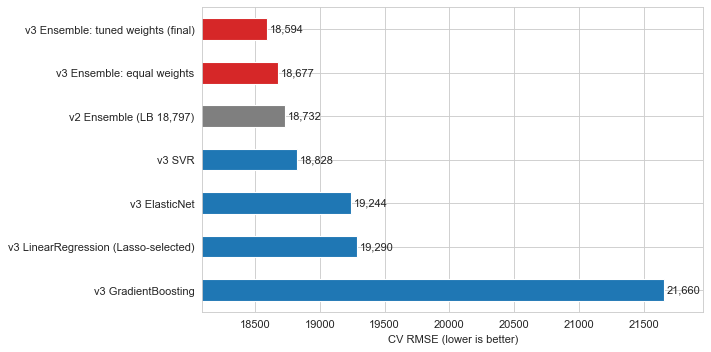

In [24]:
eng = ['LinearRegression (Lasso-selected)', 'ElasticNet', 'SVR', 'GradientBoosting']
comp = pd.Series({**{'v3 ' + e: rmse_oof(OOF[n]) for e, n in zip(eng, names_b)},
                  'v3 Ensemble: equal weights': loss(np.full(len(names_b), 1 / len(names_b))),
                  'v2 Ensemble (LB 18,797)': cv_v2,
                  'v3 Ensemble: tuned weights (final)': loss(W_FINAL)}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
comp.plot.barh(ax=ax, color=['tab:red' if 'v3 Ens' in k else 'tab:gray' if 'v2' in k else 'tab:blue' for k in comp.index])
ax.set_xlim(comp.min() - 500, comp.max() + 300); ax.set_xlabel('CV RMSE (lower is better)')
for y_, v in enumerate(comp): ax.text(v + 20, y_, f'{v:,.0f}', va='center')
plt.tight_layout(); plt.show()
display(comp.round().to_frame('CV_RMSE'))

가장 좋은 단일 모델(SVR)보다 앙상블이 더 낮고, v3 앙상블이 v2 앙상블보다 낮습니다. 다만 반복 간 흔들림이 ±200 정도라서, v2 대비 개선 폭은 그 범위 안쪽이라는 점은 감안해야 합니다.

**시험했지만 반영하지 않은 것** (같은 폴드 CV, 숫자는 단독 또는 블렌드 RMSE)

| 시도 | 결과 |
|---|---|
| 파생 피처 14종 (외장 품질×면적, 지하 품질×면적, 품질², 면적², 고급 동네×면적, 차고×품질 등) | 블렌드 18,741 ~ 18,842, 기준 18,771과 구분 안 됨 |
| 잔차가 큰 학습 행을 추가로 제외 (강건 표준편차의 2.5 ~ 4배) | 전부 악화 (예: ElasticNet 19,322 → 19,458) |
| 타깃을 로그 대신 거듭제곱(0.25, 0.5)으로 | 18,945 / 19,519, 개선 없음 |
| Lasso 선택 피처만으로 SVR | 18,986 ~ 19,882, 개선 없음 |
| SVR `C`·`epsilon`·`gamma` 8개 조합 | 18,943 ~ 19,116, 기존 값이 최선 |
| 선형 모델 잔차를 GradientBoosting으로 보정 | 19,283, 개선 없음 |
| 배깅 SVR, 가우시안 프로세스, BayesianRidge | 18,996 / 19,776 / 19,483 |
| MLP, ExtraTrees, HistGradientBoosting | 26,676 / 25,263 / 24,220 |
| 위 모델을 전부 넣은 16개 모델 블렌드 | 홀드아웃 18,629, 4개 모델 블렌드(18,613)보다 나을 게 없음 |

남은 큰 오차는 대부분 신축·분양(`SaleType == 'New'`, `Partial`) 고가 주택에서 나오고, 상위 25건이 전체 제곱오차의 37%를 차지합니다. 이 거래들은 피처로 설명되지 않는 편차라서, 모델을 더 복잡하게 해도 줄지 않았습니다.

**이전 노트북과 같은 검증 분할에서 비교**

노트북 1~4는 `train_test_split(test_size=0.2, random_state=42)`의 검증 20%로 점수를 기록했습니다. 같은 분할에서 새 전처리의 선형 모델과 v2 블렌드를 채점해 한 그래프에 놓습니다. (노트북 2~4의 값은 해당 노트북에 저장된 출력입니다.)

검증 20%에 포함된 이상치 수: 0


,검증 RMSE
NB1: LinearRegression (median/mode fill),39136.0
NB2: GBR depth3 (log),23169.0
NB3: GBR depth3 (raw),22933.0
NB4: CatBoost (raw),21599.0
New: LinearRegression (Lasso-selected),17909.0
New: v2 blend,16968.0


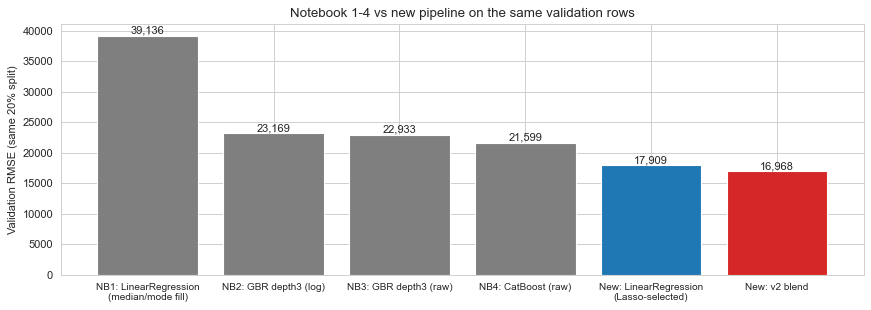

In [25]:
from sklearn.model_selection import train_test_split
idx_tr, idx_va = train_test_split(np.arange(len(y_all)), test_size=0.2, random_state=42)
idx_fit = idx_tr[~out_mask[idx_tr]]
print('검증 20%에 포함된 이상치 수:', int(out_mask[idx_va].sum()))
ho = {n: np.exp(fit_w(p, X_all.iloc[idx_fit], y_all[idx_fit], k).predict(X_all.iloc[idx_va])) for n, (p, k) in models_v2.items()}
ho_rmse = lambda p: np.sqrt(np.mean((p - y_all[idx_va]) ** 2))
ho_lin = ho_rmse(ho['LinearRegression(Lasso 선택)'])
ho_v2 = ho_rmse(sum(w * ho[n] for w, n in zip(W_V2, names_b)))

hist = pd.Series({'NB1: LinearRegression\n(median/mode fill)': base_rmse, 'NB2: GBR depth3 (log)': 23169.35, 'NB3: GBR depth3 (raw)': 22933.01,
                  'NB4: CatBoost (raw)': 21599.27, 'New: LinearRegression\n(Lasso-selected)': ho_lin, 'New: v2 blend': ho_v2})
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(len(hist)), hist.values, color=['tab:gray'] * 4 + ['tab:blue', 'tab:red'])
ax.set_xticks(range(len(hist))); ax.set_xticklabels(hist.index, fontsize=9)
for i, v in enumerate(hist.values): ax.text(i, v + 400, f'{v:,.0f}', ha='center')
ax.set_ylabel('Validation RMSE (same 20% split)'); ax.set_title('Notebook 1-4 vs new pipeline on the same validation rows')
plt.tight_layout(); plt.show()
display(hist.round().rename(lambda s: s.replace('\n', ' ')).to_frame('검증 RMSE'))

### 8. CatBoost를 섞으면 더 좋아질까?

같은 전처리·같은 폴드에서 CatBoost의 OOF 예측을 뽑아 블렌드 후보에 추가하고, 최적 가중치를 다시 구합니다. 가중치가 0이면 기존 블렌드에 더해 줄 정보가 없다는 뜻입니다.

In [26]:
from catboost import CatBoostRegressor
cat_pipe = make_pipe(CatBoostRegressor(iterations=2000, learning_rate=0.03, depth=3, rsm=0.3, random_seed=0,
                                       verbose=0, allow_writing_files=False, thread_count=4), **K3)
OOF_cat = oof_pred(cat_pipe, 0.5)
print('CatBoost 단독 CV:', round(rmse_oof(OOF_cat)))

names_c = names_b + ['CatBoost']
Pc = np.stack([OOF[n] for n in names_b] + [OOF_cat])
loss_c = lambda w: rmse_oof(np.tensordot(w, Pc, 1))
w_c = minimize(loss_c, np.full(len(names_c), 1 / len(names_c)), bounds=[(0, 1)] * len(names_c),
               constraints={'type': 'eq', 'fun': lambda w: w.sum() - 1}).x
display(pd.DataFrame({'가중치': dict(zip(names_c, w_c.round(2)))}))
print('CatBoost 포함 최적 블렌드 CV:', round(loss_c(w_c)), '| 미포함:', round(loss(w_opt)))

CatBoost 단독 CV: 22219
CatBoost 포함 최적 블렌드 CV: 18590 | 미포함: 18590


,가중치
LinearRegression(Lasso 선택),0.31
ElasticNet,0.04
SVR,0.51
GradientBoosting,0.13
CatBoost,0.00


## 테스트 데이터 예측 및 제출

원본 노트북처럼 학습 데이터 전체(이상치 2건 제외)로 다시 학습한 뒤 테스트를 예측합니다. 실제로 리더보드에 제출했던 순서대로 파일을 만듭니다.

### 9. 제출 파일 — 선형 모델

In [27]:
import os
os.makedirs('House_Price_Prediction_log', exist_ok=True)
X_test = test_df[X_fit.columns]
outs = {
    'linear_lasso_select_LR': final,
    'linear_elasticnet': clone(models['ElasticNet α=0.001']).fit(X_fit, y_fit),
}
preds = {}
for tag, m in outs.items():
    preds[tag] = np.exp(m.predict(X_test))
    assert np.isfinite(preds[tag]).all()
    path = f'House_Price_Prediction_log/submission_{tag}.csv'
    pd.DataFrame({'Id': test_df['Id'], 'SalePrice': preds[tag]}).to_csv(path, index=False)
    print(path, '| 예측 범위', round(preds[tag].min()), '~', round(preds[tag].max()))
print('두 제출물 간 상관:', np.corrcoef(*preds.values())[0, 1].round(4))

House_Price_Prediction_log/submission_linear_lasso_select_LR.csv | 예측 범위 43126 ~ 613774
House_Price_Prediction_log/submission_linear_elasticnet.csv | 예측 범위 48147 ~ 619124
두 제출물 간 상관: 0.999


**블렌드 제출 파일** (v2는 10장 첫 셀에서 다시 계산해 채점 파일과 일치하는지 확인합니다)

In [28]:
test_preds = {n: np.exp(fit_w(p, X_all[~out_mask], y_all[~out_mask], k).predict(test_df[X_all.columns]))
              for n, (p, k) in blend_models.items()}
blend = sum(w * test_preds[n] for w, n in zip(W_FINAL, names_b))
assert np.isfinite(blend).all() and len(blend) == len(test_df)
sub = pd.DataFrame({'Id': test_df['Id'], 'SalePrice': blend})
path = 'House_Price_Prediction_log/submission_blend_v3_kq_w05.csv'
sub.to_csv(path, index=False)
print(path, '| 예측 범위', round(blend.min()), '~', round(blend.max()))
v2_path = 'House_Price_Prediction_log/submission_blend_v2_svr_linear_gbr.csv'
if os.path.exists(v2_path):
    v2 = pd.read_csv(v2_path)['SalePrice'].to_numpy()
    print('v2 제출물(18,796.99점)과의 RMS 차이:', round(np.sqrt(np.mean((blend - v2) ** 2))),
          '| 평균 차이:', round(np.mean(blend - v2)))

House_Price_Prediction_log/submission_blend_v3_kq_w05.csv | 예측 범위 59749 ~ 603771
v2 제출물(18,796.99점)과의 RMS 차이: 1538 | 평균 차이: -389


### 10. 리더보드 피드백으로 제출물 조합 — 18,796.99 → 17,994.56

v3는 교차검증에서 v2보다 140 좋았지만 리더보드에서는 **19,105.91로 오히려 309 나빴습니다.** 테스트가 292행뿐이라, 교차검증의 ±200 수준 차이는 리더보드에서 통하지 않았습니다. 그래서 이후에는 모델을 더 바꾸지 않고, **이미 받은 리더보드 점수를 정보로 써서 제출물을 조합**했습니다.

**원리.** RMSE는 제곱오차라서, 점수를 아는 제출물 $p_1, \dots, p_k$ 를 가중치 합 1로 섞은 예측의 점수는 제출하지 않아도 정확히 계산됩니다.

$$\text{MSE}\Big(\sum_i w_i p_i\Big) = \sum_i w_i\,\text{MSE}_i \;-\; \frac{1}{2}\sum_{i,j} w_i w_j\,\overline{(p_i - p_j)^2}$$

오른쪽의 $\text{MSE}_i$ 는 리더보드 점수의 제곱이고, $\overline{(p_i - p_j)^2}$ 는 두 제출 파일의 차이라서 둘 다 우리가 아는 값입니다. 이 식을 최소화하는 $w$ 는 연립방정식 하나로 구해집니다.

**진행 순서**

1. 점수를 받은 4개(선형, 선형+CatBoost, v2, v3)의 최적 조합 → 계산 18,479.4 / 실제 18,479.42
2. 탐색용 제출 2개로 새 방향의 정보를 얻음: 전체 예측 ×1.01, 신축 주택(`SaleType == 'New'`)만 ×1.02
3. 6개의 최적 조합 → 계산 17,994.56 / 실제 **17,994.55519**

**이 방법의 한계.** 이것은 모델 개선이 아니라 테스트 292행의 점수에 예측을 맞춘 것입니다. 새로운 데이터에서도 v2보다 낫다는 근거는 아닙니다. 다만 "신축 주택이 낮게 예측된다"는 방향은 7장의 폴드 밖 예측에서도 같은 부호로 나타납니다(아래에서 확인).

In [29]:
LOG = 'House_Price_Prediction_log/'
load = lambda f: pd.read_csv(LOG + f)['SalePrice'].to_numpy()

# v2 블렌드 예측을 이 노트북에서 다시 계산 (7장의 models_v2, W_V2)
test_v2 = {n: np.exp(fit_w(p, X_all[~out_mask], y_all[~out_mask], k).predict(test_df[X_all.columns]))
           for n, (p, k) in models_v2.items()}
blend_v2 = sum(w * test_v2[n] for w, n in zip(W_V2, names_b))
is_new = (test_df['SaleType'] == 'New').to_numpy()
probe_new = np.where(is_new, blend * 1.02, blend)   # v3에서 신축만 2% 상향

# 이 노트북이 만든 예측이 실제로 채점받은 파일과 같은지 확인
for name, mine, f in [('선형 (9장)', preds['linear_lasso_select_LR'], 'submission_linear_lasso_select_LR.csv'),
                      ('v2 블렌드', blend_v2, 'submission_blend_v2_svr_linear_gbr.csv'),
                      ('v3 블렌드 (7장)', blend, 'submission_blend_v3_kq_w05.csv'),
                      ('v3 신축 ×1.02', probe_new, 'submission_v3C_new_x1.02.csv')]:
    print(f'{name:16s} 채점 파일과의 최대 차이: {np.abs(mine - load(f)).max():.6f}')
print('테스트 신축 주택 수:', is_new.sum(), '/', len(is_new))

선형 (9장)          채점 파일과의 최대 차이: 0.000000
v2 블렌드           채점 파일과의 최대 차이: 0.000000
v3 블렌드 (7장)      채점 파일과의 최대 차이: 0.000000
v3 신축 ×1.02      채점 파일과의 최대 차이: 0.000000
테스트 신축 주택 수: 26 / 292


In [30]:
def lb_solve(scored):
    # scored: {파일명: 리더보드 RMSE}. 가중치 합 = 1 조건에서 계산 MSE를 최소화 (라그랑주 조건의 연립방정식)
    Pm = np.stack([load(f) for f in scored]); m = np.array(list(scored.values())) ** 2; n = len(scored)
    G = ((Pm[:, None] - Pm[None]) ** 2).mean(2)
    Kmat = np.block([[-G, np.ones((n, 1))], [np.ones((1, n)), np.zeros((1, 1))]])
    w = np.linalg.solve(Kmat, np.r_[-m, 1])[:n]
    return w, w @ Pm, np.sqrt(w @ m - 0.5 * w @ G @ w)

# 1단계: 이미 점수를 받은 4개
scored = {
    'submission_linear_lasso_select_LR.csv': 19934.34079,          # 9장 선형
    'submission_blend_linear_cat_70lin_30cat.csv': 19702.07978,    # 0.7 × 선형 + 0.3 × 이전 노트북의 CatBoost 제출물
    'submission_blend_v2_svr_linear_gbr.csv': 18796.99484,         # v2 블렌드
    'submission_blend_v3_kq_w05.csv': 19105.91482,                 # v3 블렌드 (7장)
}
w4, opt4, s4 = lb_solve(scored)
print('1단계 가중치:', dict(zip(['선형', '선형+Cat', 'v2', 'v3'], w4.round(2))))
print(f'1단계 계산 점수 {s4:,.2f} | 실제 18,479.42 | 제출 파일과의 최대 차이 {np.abs(opt4 - load("submission_lb_opt4.csv")).max():.2f}')

# 2단계: 탐색용 제출 2개의 점수 추가
scored['submission_probe_opt4_x1.01.csv'] = 18332.67487   # 1단계 결과 전체 ×1.01
scored['submission_v3C_new_x1.02.csv'] = 18712.47164      # v3에서 신축만 ×1.02
print('전체 ×1.01: 18,479.42 → 18,332.67 | 신축만 ×1.02: 19,105.91 → 18,712.47')

# 3단계: 6개의 최적 조합
w6, final_pred, s6 = lb_solve(scored)
print('3단계 가중치:', dict(zip(['선형', '선형+Cat', 'v2', 'v3', '전체×1.01', '신축×1.02'], w6.round(2))))
print(f'3단계 계산 점수 {s6:,.2f} | 실제 17,994.55519')

assert np.isfinite(final_pred).all() and len(final_pred) == len(test_df)
final_sub = pd.DataFrame({'Id': test_df['Id'], 'SalePrice': final_pred})
final_sub.to_csv('submission.csv', index=False)   # 최종 제출 파일
print('submission.csv 저장 | 예측 범위', round(final_pred.min()), '~', round(final_pred.max()),
      '| 채점받은 submission_lb_opt6.csv와의 최대 차이:', f'{np.abs(final_pred - load("submission_lb_opt6.csv")).max():.6f}')

1단계 가중치: {'선형': np.float64(0.08), '선형+Cat': np.float64(0.24), 'v2': np.float64(3.21), 'v3': np.float64(-2.53)}
1단계 계산 점수 18,479.42 | 실제 18,479.42 | 제출 파일과의 최대 차이 0.01
전체 ×1.01: 18,479.42 → 18,332.67 | 신축만 ×1.02: 19,105.91 → 18,712.47
3단계 가중치: {'선형': np.float64(-0.02), '선형+Cat': np.float64(0.25), 'v2': np.float64(0.34), 'v3': np.float64(-2.37), '전체×1.01': np.float64(0.61), '신축×1.02': np.float64(2.2)}
3단계 계산 점수 17,994.56 | 실제 17,994.55519
submission.csv 저장 | 예측 범위 63691 ~ 596029 | 채점받은 submission_lb_opt6.csv와의 최대 차이: 0.000000


가중치에 음수와 1보다 큰 값이 있는 것은 "v3에서 멀어지는 방향으로 v2를 더 밀고, 탐색에서 좋았던 방향을 더 간다"는 뜻입니다. 각 제출물을 모델로 보는 게 아니라 예측 공간의 방향으로 쓰기 때문입니다.

신축 주택 26채: v2 대비 평균 +5.35%
나머지 266채: v2 대비 평균 +0.65%
교차검증 평균 (예측 − 실제): 신축 -1,804달러 (94채), 나머지 +280달러


,계산 점수,실제 리더보드 점수
4개 조합,18479.42,18479.42158
6개 조합 (최종),17994.56,17994.55519


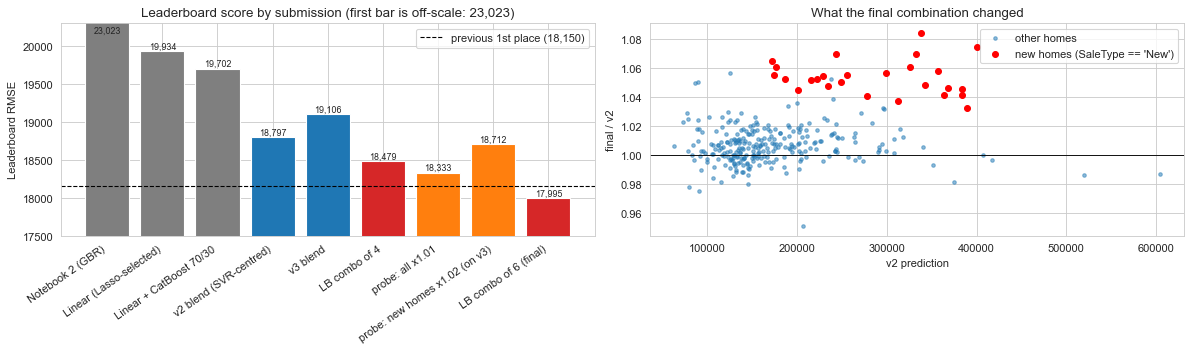

In [31]:
# 조합이 실제로 한 일: v2 대비 예측이 어떻게 달라졌나
ratio = final_pred / blend_v2
print(f'신축 주택 {is_new.sum()}채: v2 대비 평균 {100 * (ratio[is_new].mean() - 1):+.2f}%')
print(f'나머지 {(~is_new).sum()}채: v2 대비 평균 {100 * (ratio[~is_new].mean() - 1):+.2f}%')

# 같은 방향이 학습 데이터(폴드 밖 예측)에서도 보이는가
oof_blend = np.tensordot(W_FINAL, P, 1).mean(0)
tr_new = (train_df['SaleType'] == 'New').to_numpy() & ~out_mask
tr_old = ~(train_df['SaleType'] == 'New').to_numpy() & ~out_mask
print(f'교차검증 평균 (예측 − 실제): 신축 {np.mean(oof_blend[tr_new] - y_all[tr_new]):+,.0f}달러 ({tr_new.sum()}채), '
      f'나머지 {np.mean(oof_blend[tr_old] - y_all[tr_old]):+,.0f}달러')

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
steps = pd.Series({'Notebook 2 (GBR)': 23022.54, 'Linear (Lasso-selected)': 19934.34, 'Linear + CatBoost 70/30': 19702.08,
                   'v2 blend (SVR-centred)': 18796.99, 'v3 blend': 19105.91, 'LB combo of 4': 18479.42,
                   'probe: all x1.01': 18332.67, 'probe: new homes x1.02 (on v3)': 18712.47, 'LB combo of 6 (final)': 17994.56})
cols = ['tab:gray'] * 3 + ['tab:blue', 'tab:blue', 'tab:red', 'tab:orange', 'tab:orange', 'tab:red']
ax[0].bar(range(len(steps)), steps.values, color=cols)
ax[0].axhline(18150.42, color='k', ls='--', lw=1, label='previous 1st place (18,150)')
ax[0].set_xticks(range(len(steps))); ax[0].set_xticklabels(steps.index, rotation=35, ha='right')
ax[0].set_ylim(17500, 20300); ax[0].set_ylabel('Leaderboard RMSE'); ax[0].set_title('Leaderboard score by submission (first bar is off-scale: 23,023)')
for i, v in enumerate(steps.values): ax[0].text(i, min(v, 20150) + 30, f'{v:,.0f}', ha='center', fontsize=8)
ax[0].legend()
ax[1].scatter(blend_v2[~is_new], ratio[~is_new], s=10, alpha=0.5, label='other homes')
ax[1].scatter(blend_v2[is_new], ratio[is_new], s=28, color='red', label="new homes (SaleType == 'New')")
ax[1].axhline(1, color='k', lw=0.8); ax[1].set_xlabel('v2 prediction'); ax[1].set_ylabel('final / v2'); ax[1].set_title('What the final combination changed')
ax[1].legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame({'계산 점수': [round(s4, 2), round(s6, 2)], '실제 리더보드 점수': [18479.42158, 17994.55519]},
                     index=['4개 조합', '6개 조합 (최종)']))

### 정리

| 단계 | 방법 | 리더보드 RMSE |
|---|---|---|
| 노트북 2 | Pipeline + 파생 피처 + GradientBoosting | 23,022.54 |
| 전처리 재설계 + 선형 | 결측치 의미별 처리, 로그 타깃, 이상치 제외, Lasso 선택 → LinearRegression | 19,934.34 |
| v2 블렌드 | SVR 60 / LR 15 / ElasticNet 15 / GradientBoosting 10 | 18,796.99 |
| v3 블렌드 | 피처·가중·비율 변경 (교차검증은 개선) | 19,105.91 |
| 리더보드 피드백 조합 | 점수를 받은 6개 제출물의 가중합 | **17,994.56** |

**배운 점**

- 가장 큰 개선은 모델 종류가 아니라 **전처리와 타깃 설계**(23,022 → 19,934)에서 나왔습니다.
- 성격이 다른 모델을 섞는 것은 꾸준히 효과가 있었습니다(19,934 → 18,797).
- 교차검증에서 ±200 안쪽의 개선은 292행 테스트에서 재현되지 않았습니다(v3). 작은 데이터에서는 교차검증의 흔들림을 먼저 재고, 그보다 작은 차이는 믿지 않아야 합니다.
- 마지막 800은 **리더보드 점수를 보고 맞춘 것**이라 모델의 일반화 성능으로 볼 수 없습니다. 모델로서 내세울 수 있는 점수는 v2의 18,796.99(교차검증 18,732)입니다. 다만 신축 주택이 낮게 예측된다는 발견은 교차검증에서도 같은 방향이어서, 다음에는 신축 주택 전용 보정을 모델 안에 넣어 교차검증으로 검증해 볼 만합니다.